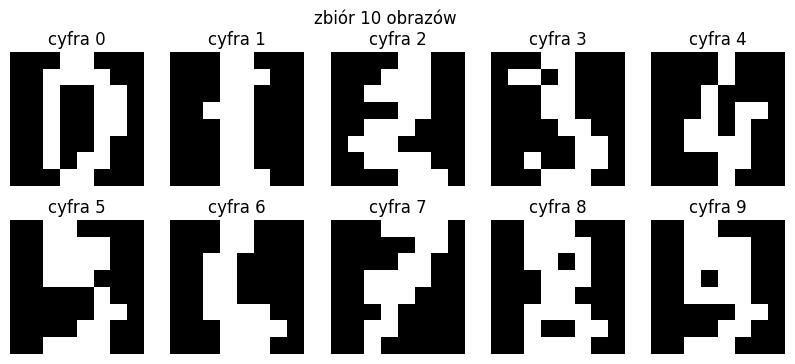

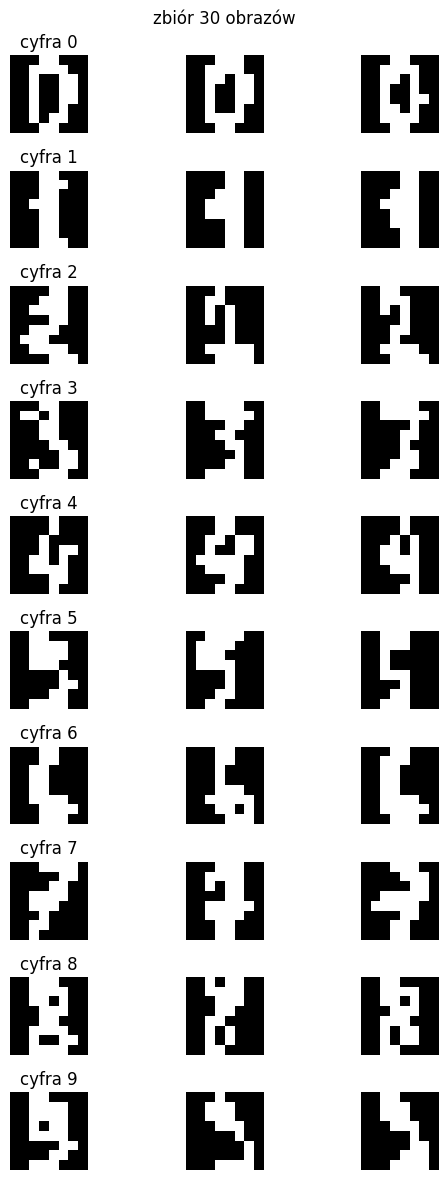

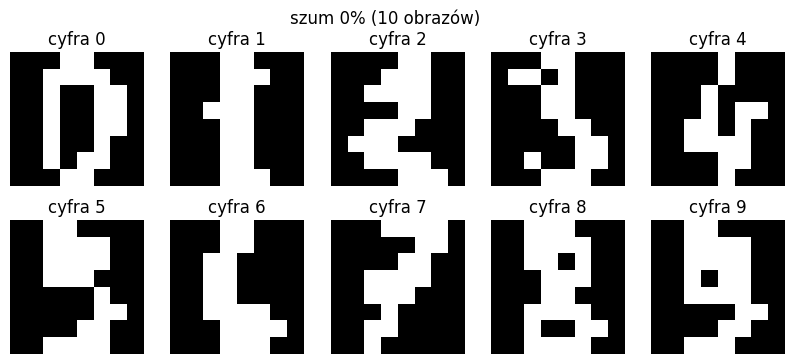

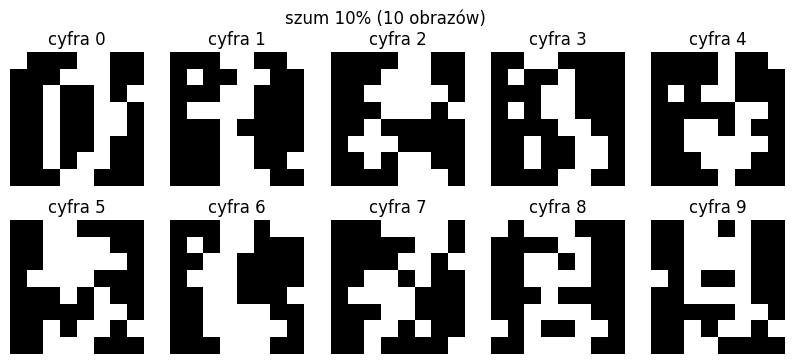

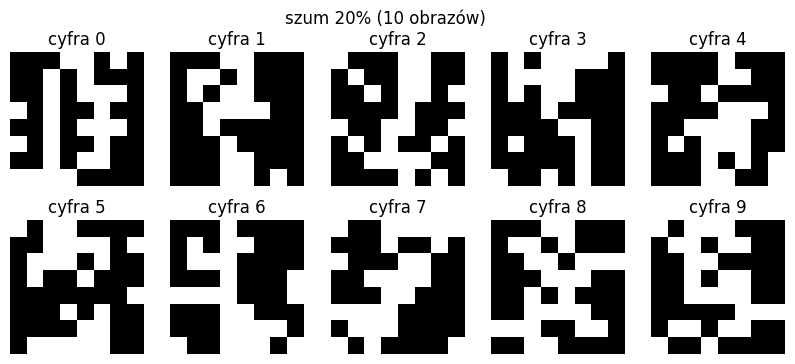

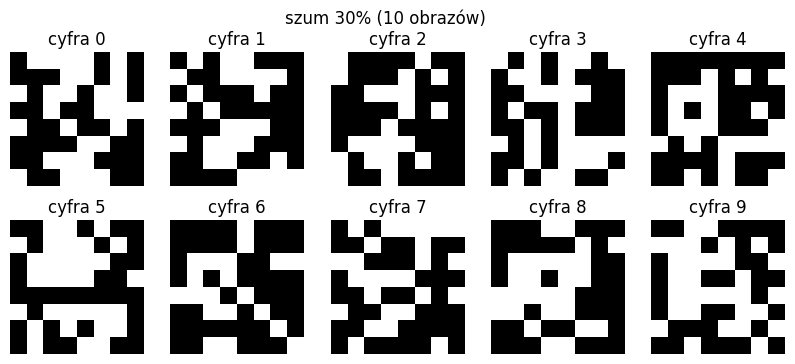

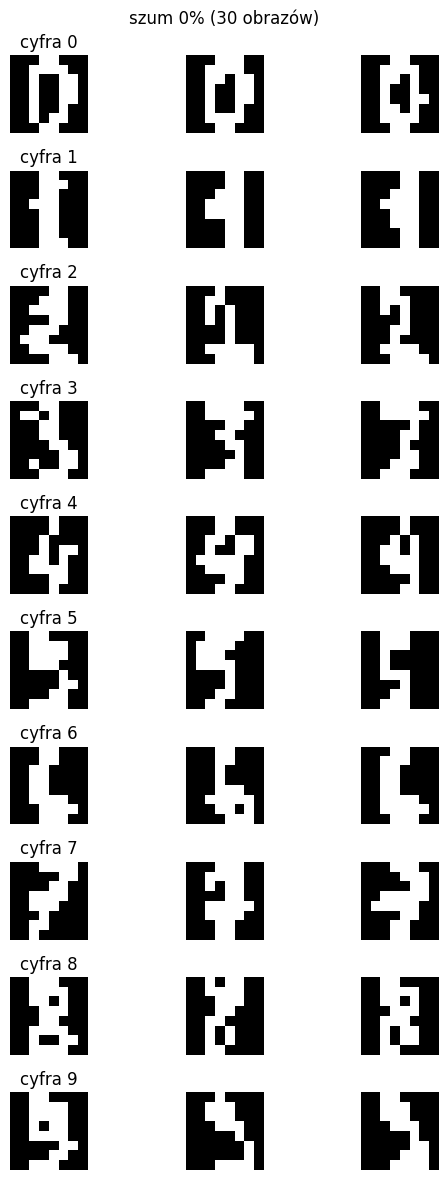

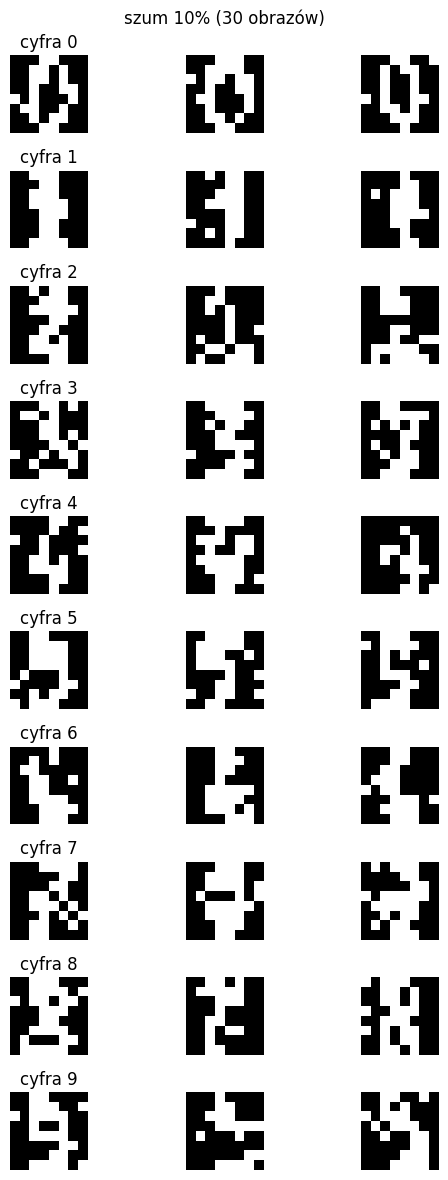

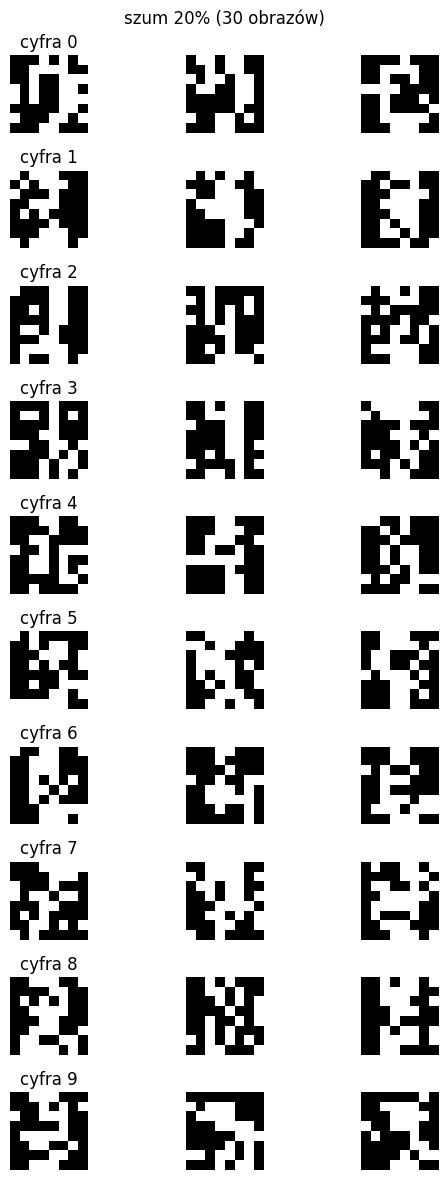

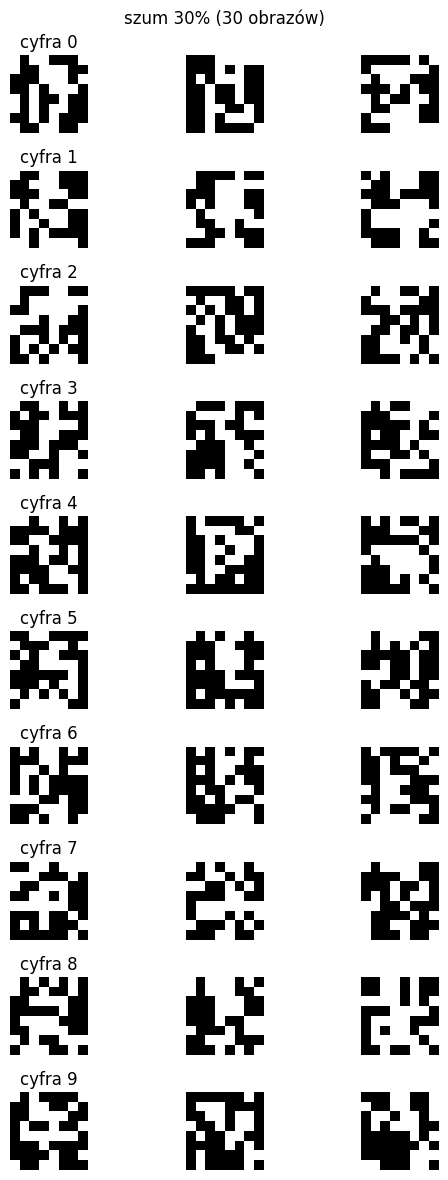

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()

X = digits.data
Y = digits.target

digits_1 = []
digits_2 = []

for i in range(10):
    number = X[Y == i]
    digits_1.append(number[0])

    for j in range(3):
        digits_2.append(number[j])

digits_1 = np.array(digits_1)
digits_2 = np.array(digits_2)

digits_1 = np.where(digits_1 > 7, 1, -1)
digits_2 = np.where(digits_2 > 7, 1, -1)

def wyswietl_zbior_10(zbior, tytul="zbiór 10 obrazów"):
    fig, axes = plt.subplots(2, 5, figsize=(10, 4))
    fig.suptitle(tytul)

    for i, ax in enumerate(axes.flat):
        ax.imshow(zbior[i].reshape(8, 8), cmap='gray')
        ax.axis('off')
        ax.set_title(f"cyfra {i}")

    plt.show()

wyswietl_zbior_10(digits_1)

def wyswietl_zbior_30(zbior, tytul="zbiór 30 obrazów"):
    fig, axes = plt.subplots(10, 3, figsize=(6, 12))
    fig.suptitle(tytul)

    for i in range(10):
        for j in range(3):
            indeks = i * 3 + j
            axes[i, j].imshow(zbior[indeks].reshape(8, 8), cmap='gray')
            axes[i, j].axis('off')

            if j == 0:
                axes[i, j].set_title(f"cyfra {i}")

    plt.tight_layout()
    plt.show()

wyswietl_zbior_30(digits_2)

def szum(o, p):
    zaszumiony = np.copy(o)
    liczba_pikseli = int(64 * p)

    indeks = np.random.choice(64, size=liczba_pikseli, replace=False)
    zaszumiony[indeks] *= -1
    return zaszumiony

def zaszum_zbior(z, p):
    zaszumione = [szum(o, p) for o in z]
    return np.array(zaszumione)

wyswietl_zbior_10(digits_1, "szum 0% (10 obrazów)")
digits_1_szum_10 = zaszum_zbior(digits_1, 0.10)
wyswietl_zbior_10(digits_1_szum_10, "szum 10% (10 obrazów)")
digits_1_szum_20 = zaszum_zbior(digits_1, 0.20)
wyswietl_zbior_10(digits_1_szum_20, "szum 20% (10 obrazów)")
digits_1_szum_30 = zaszum_zbior(digits_1, 0.30)
wyswietl_zbior_10(digits_1_szum_30, "szum 30% (10 obrazów)")

wyswietl_zbior_30(digits_2, "szum 0% (30 obrazów)")
digits_2_szum_10 = zaszum_zbior(digits_2, 0.10)
wyswietl_zbior_30(digits_2_szum_10, "szum 10% (30 obrazów)")
digits_2_szum_20 = zaszum_zbior(digits_2, 0.20)
wyswietl_zbior_30(digits_2_szum_20, "szum 20% (30 obrazów)")
digits_2_szum_30 = zaszum_zbior(digits_2, 0.30)
wyswietl_zbior_30(digits_2_szum_30, "szum 30% (30 obrazów)")


liczba_neuronow = 64


def trenuj_hebba(wzorce):
    W = np.zeros((liczba_neuronow, liczba_neuronow))
    for wzorzec in wzorce:
        W += np.outer(wzorzec, wzorzec)

    np.fill_diagonal(W, 0)

    W = W / liczba_neuronow
    return W

def odtworz_wzorzec(wzorzec, W, maks_epok=15):
    s = np.copy(wzorzec)

    for epoka in range(maks_epok):
        kolejnosc = np.random.permutation(liczba_neuronow)
        zmiany = 0

        for i in kolejnosc:
            h_i = np.dot(W[i, :], s)
            stary_stan = s[i]

            if h_i > 0:
                s[i] = 1
            elif h_i < 0:
                s[i] = -1

            if s[i] != stary_stan:
                zmiany += 1

        if zmiany == 0:
            break

    return s

def odtworz_zbior(zbior_zaszumiony, W):
    return np.array([odtworz_wzorzec(obraz, W) for obraz in zbior_zaszumiony])

def porownaj_wyniki(oryginaly, zaszumione, zrekonstruowane, tytul="Porównanie rekonstrukcji"):
    liczba_obrazow = len(oryginaly)

    fig, axes = plt.subplots(liczba_obrazow, 3, figsize=(6, 1.2 * liczba_obrazow))
    fig.suptitle(tytul)

    for i in range(liczba_obrazow):
        axes[i, 0].imshow(oryginaly[i].reshape(8, 8), cmap='gray')
        axes[i, 0].axis('off')
        if i == 0: axes[i, 0].set_title("Oryginał")

        axes[i, 1].imshow(zaszumione[i].reshape(8, 8), cmap='gray')
        axes[i, 1].axis('off')
        if i == 0: axes[i, 1].set_title("Zaszumiony")

        axes[i, 2].imshow(zrekonstruowane[i].reshape(8, 8), cmap='gray')
        axes[i, 2].axis('off')
        if i == 0: axes[i, 2].set_title("Odtworzony")

    plt.tight_layout()
    plt.show()



Czy macierz wag jest symetryczna? True
Czy na przekątnej są zera? True


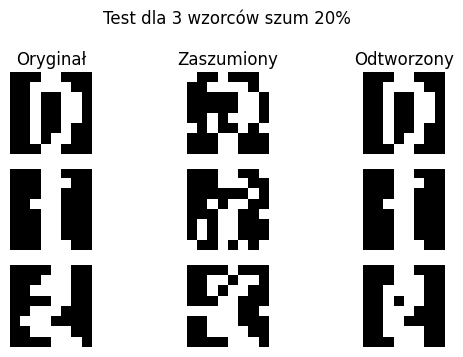

In [15]:
wzorce_do_nauki = digits_1[:3]

W = trenuj_hebba(wzorce_do_nauki)

print("Czy macierz wag jest symetryczna?", np.allclose(W, W.T))
print("Czy na przekątnej są zera?", np.all(np.diag(W) == 0))

test_szum = zaszum_zbior(wzorce_do_nauki, 0.20)

test_odtworzone = odtworz_zbior(test_szum, W)

porownaj_wyniki(wzorce_do_nauki, test_szum, test_odtworzone, tytul="Test dla 3 wzorców szum 20%")


Sprawdzenie macierzy pseudoinwersja:
Czy symetryczna? True
Czy ma zera na przekątnej? True

Sprawdzenie macierzy storkey:
Czy symetryczna? True
Czy ma zera na przekątnej? True

--- ODTWARZANIE WZORCÓW Z SZUMU ---
Wyniki dla reguły Hebba:


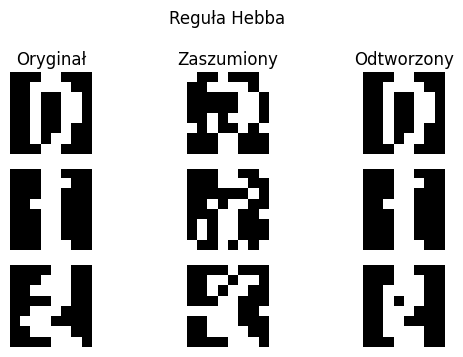

Wyniki dla reguły Pseudoinwersji:


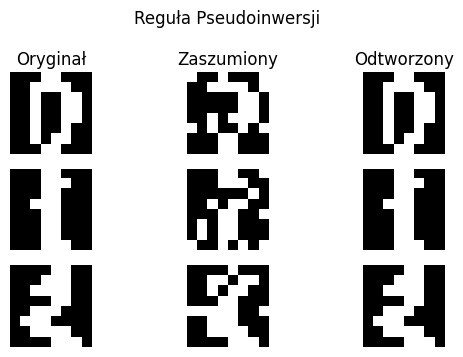

Wyniki dla reguły Storkeya:


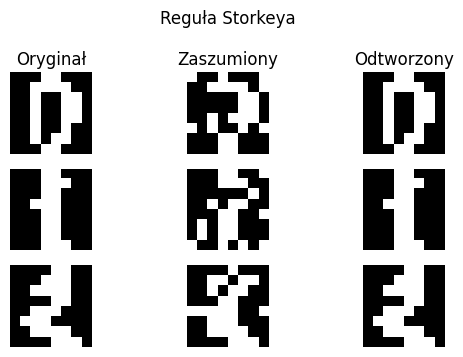

In [16]:

def trenuj_pseudoinwersja(wzorce):

    X = np.array(wzorce)

    pseudo_odwrotnosc = np.linalg.pinv(X @ X.T)
    W = X.T @ pseudo_odwrotnosc @ X

    np.fill_diagonal(W, 0)

    return W

def trenuj_storkeya(wzorce, liczba_neuronow=64):

    W = np.zeros((liczba_neuronow, liczba_neuronow))
    N = liczba_neuronow

    for wzorzec in wzorce:
        W_nowe = np.copy(W)

        h = W @ wzorzec

        for i in range(N):
            for j in range(N):
                if i == j:
                    continue

                h_ij = h[i] - W[i, j] * wzorzec[j]
                h_ji = h[j] - W[j, i] * wzorzec[i]

                zmiana = (wzorzec[i] * wzorzec[j] - wzorzec[i] * h_ji - wzorzec[j] * h_ij) / N
                W_nowe[i, j] += zmiana

        W = W_nowe
        np.fill_diagonal(W, 0)

    return W

W_hebb = trenuj_hebba(wzorce_do_nauki)
W_pseudo = trenuj_pseudoinwersja(wzorce_do_nauki)
W_storkey = trenuj_storkeya(wzorce_do_nauki)


print("\nSprawdzenie macierzy pseudoinwersja:")
print("Czy symetryczna?", np.allclose(W_pseudo, W_pseudo.T))
print("Czy ma zera na przekątnej?", np.allclose(np.diag(W_pseudo), 0))

print("\nSprawdzenie macierzy storkey:")
print("Czy symetryczna?", np.allclose(W_storkey, W_storkey.T, atol=1e-8))
print("Czy ma zera na przekątnej?", np.allclose(np.diag(W_storkey), 0))


print("\n--- ODTWARZANIE WZORCÓW Z SZUMU ---")
odtworzone_hebb = odtworz_zbior(test_szum, W_hebb)
odtworzone_pseudo = odtworz_zbior(test_szum, W_pseudo)
odtworzone_storkey = odtworz_zbior(test_szum, W_storkey)

print("Wyniki dla reguły Hebba:")
porownaj_wyniki(wzorce_do_nauki, test_szum, odtworzone_hebb, tytul="Reguła Hebba")

print("Wyniki dla reguły Pseudoinwersji:")
porownaj_wyniki(wzorce_do_nauki, test_szum, odtworzone_pseudo, tytul="Reguła Pseudoinwersji")

print("Wyniki dla reguły Storkeya:")
porownaj_wyniki(wzorce_do_nauki, test_szum, odtworzone_storkey, tytul="Reguła Storkeya")